# IV Infiltration Monitoring — Research Audit Notebook

This notebook helps audit the evidence before you present results. It separates:
1. The clinical paired-measurement dataset (18 patients, if the source table is available).
2. The synthetic dataset and signal/label timing.
3. Reported model metrics and the real-time window timestamp issue.

**Important:** synthetic-data accuracy is not clinical validation. Run from the project root (the folder containing `synthetic_iv_infiltration_dataset.csv`) or edit `PROJECT_ROOT` below. Run cells in order.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
# If needed, set explicitly, e.g.:
# PROJECT_ROOT = Path(r"C:\mer\iot projecttt\iv-infiltration-project")

SYNTHETIC_CSV = PROJECT_ROOT / "synthetic_iv_infiltration_dataset.csv"
CLINICAL_DIR = PROJECT_ROOT / "data" / "clinical_plos_one"
RESULTS_A = PROJECT_ROOT / "results" / "workstream_a"
RESULTS_B = PROJECT_ROOT / "results" / "workstream_b"

print("Project root:", PROJECT_ROOT.resolve())
for p in [SYNTHETIC_CSV, CLINICAL_DIR, RESULTS_A, RESULTS_B]:
    print(("FOUND: " if p.exists() else "MISSING: ") + str(p))

Project root: C:\mer\iot projecttt\iv-infiltration-project
FOUND: C:\mer\iot projecttt\iv-infiltration-project\synthetic_iv_infiltration_dataset.csv
FOUND: C:\mer\iot projecttt\iv-infiltration-project\data\clinical_plos_one
FOUND: C:\mer\iot projecttt\iv-infiltration-project\results\workstream_a
FOUND: C:\mer\iot projecttt\iv-infiltration-project\results\workstream_b


## 1. Locate and inspect the clinical data

The clinical dataset must be treated as paired patient measurements, not as a continuous real-time temperature/pressure recording. First identify the source file and inspect its columns.

In [3]:
clinical_files = []
if CLINICAL_DIR.exists():
    clinical_files = [p for p in CLINICAL_DIR.rglob("*")
                      if p.is_file() and p.suffix.lower() in {".csv", ".xlsx", ".xls", ".json"}]
print("Clinical candidate files:")
for p in clinical_files:
    print(" -", p.relative_to(PROJECT_ROOT))

# Set this after inspecting the list above. Do not select a predictions/results file as raw data.
CLINICAL_FILE = None
# Example:
# CLINICAL_FILE = PROJECT_ROOT / "data" / "clinical_plos_one" / "parsed_measurements.csv"

clinical_df = None
if CLINICAL_FILE is not None:
    p = Path(CLINICAL_FILE)
    if p.suffix.lower() == ".csv":
        clinical_df = pd.read_csv(p)
    elif p.suffix.lower() in {".xlsx", ".xls"}:
        clinical_df = pd.read_excel(p)
    elif p.suffix.lower() == ".json":
        clinical_df = pd.read_json(p)
    print("Shape:", clinical_df.shape)
    print("Columns:", clinical_df.columns.tolist())
    display(clinical_df.head())
    display(clinical_df.isna().sum().to_frame("missing_count"))
else:
    print("Set CLINICAL_FILE to the verified raw/parsed clinical measurement file, then rerun this cell.")

Clinical candidate files:
 - data\clinical_plos_one\Cm.csv
 - data\clinical_plos_one\pone.0213585.s001.xlsx
 - data\clinical_plos_one\R.csv
 - data\clinical_plos_one\Xc.csv
 - data\clinical_plos_one\Z.csv
Set CLINICAL_FILE to the verified raw/parsed clinical measurement file, then rerun this cell.


### Clinical interpretation checklist

Before computing statistics, verify what each row represents, how patient ID / before-after timepoint / frequency / parameter are encoded, units, missing values, and whether each patient has paired measurements. The patient is the unit for paired inference. Do not treat 36 before/after observations as 36 independent patients.

## 2. Load and inspect the synthetic sensor dataset

In [4]:
if not SYNTHETIC_CSV.exists():
    raise FileNotFoundError(f"Cannot find {SYNTHETIC_CSV}. Set PROJECT_ROOT to your repo root.")

df = pd.read_csv(SYNTHETIC_CSV)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

required = {"trial_id", "time_s", "label", "severity", "condition"}
print("Required columns missing:", sorted(required - set(df.columns)))

if {"trial_id", "time_s"}.issubset(df.columns):
    trial_summary = df.groupby("trial_id").agg(
        rows=("time_s", "size"),
        start_s=("time_s", "min"),
        end_s=("time_s", "max"),
        unique_times=("time_s", "nunique")
    )
    print("Trials:", df["trial_id"].nunique())
    print("Trials with duplicate timestamps:", int((trial_summary["unique_times"] != trial_summary["rows"]).sum()))
    display(trial_summary.describe().T)

for col in ["severity", "condition", "label"]:
    if col in df.columns:
        if col == "label":
            display(df[col].value_counts(dropna=False).sort_index().to_frame("timestep_count"))
        else:
            display(df.groupby("trial_id")[col].first().value_counts(dropna=False).to_frame("trial_count"))

Rows: 360000
Columns: ['trial_id', 'time_s', 'temperature_c', 'pressure_adc', 'condition', 'severity', 'label', '_static_label_GT', '_leak_rate_mlph_GT', '_leaked_volume_ml_GT']


,trial_id,time_s,temperature_c,pressure_adc,condition,severity,label,_static_label_GT,_leak_rate_mlph_GT,_leaked_volume_ml_GT
0,0,0.0,32.8125,1170.0,normal,none,0,0,0.0,0.0
1,0,1.0,32.8750,1153.0,normal,none,0,0,0.0,0.0
2,0,2.0,32.6875,1168.0,normal,none,0,0,0.0,0.0
3,0,3.0,32.6250,1160.0,normal,none,0,0,0.0,0.0
4,0,4.0,32.5000,1167.0,normal,none,0,0,0.0,0.0


Required columns missing: []
Trials: 200
Trials with duplicate timestamps: 0


,count,mean,std,min,25%,50%,75%,max
rows,200.0,1800.0,0.0,1800.0,1800.0,1800.0,1800.0,1800.0
start_s,200.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
end_s,200.0,1799.0,0.0,1799.0,1799.0,1799.0,1799.0,1799.0
unique_times,200.0,1800.0,0.0,1800.0,1800.0,1800.0,1800.0,1800.0


,trial_count
severity,
none,50
early,50
moderate,50
severe,50


,trial_count
condition,
normal,40
noisy_temp,40
noisy_pressure,40
missing_temp,40
missing_pressure,40


,timestep_count
label,
0,199159
1,100284
2,49446
3,11111


## 3. Signal-versus-label timing audit

The next cell estimates when sensor signals first deviate from an early-trial baseline and compares that with the first positive label. This is only a heuristic diagnostic; it is not proof of leakage. Inspect plots and simulator equations before drawing conclusions.

In [5]:
sensor_cols = [c for c in ["temperature_c", "pressure_adc"] if c in df.columns]
timing_rows = []

for tid, g in df.groupby("trial_id"):
    g = g.sort_values("time_s")
    t = g["time_s"].to_numpy(dtype=float)
    row = {
        "trial_id": tid,
        "severity": g["severity"].iloc[0] if "severity" in g else None,
        "condition": g["condition"].iloc[0] if "condition" in g else None
    }
    if "label" in g:
        y = g["label"].to_numpy(dtype=int)
        positive_idx = np.flatnonzero(y >= 1)
        row["label_onset_s"] = t[positive_idx[0]] if len(positive_idx) else np.nan
    for col in sensor_cols:
        x = g[col].to_numpy(dtype=float)
        nbase = max(5, min(len(g)//10, 60))
        baseline = x[:nbase]
        med = np.nanmedian(baseline)
        mad = np.nanmedian(np.abs(baseline - med))
        scale = 1.4826 * mad
        if not np.isfinite(scale) or scale < 1e-9:
            scale = np.nanstd(baseline)
        threshold = max(3 * (scale if np.isfinite(scale) else 0), 1e-6)
        dev_idx = np.flatnonzero(np.abs(x - med) > threshold)
        row[f"{col}_first_deviation_s"] = t[dev_idx[0]] if len(dev_idx) else np.nan
    timing_rows.append(row)

timing_df = pd.DataFrame(timing_rows)
display(timing_df.head(20))
if not timing_df.empty and "severity" in timing_df:
    cols = [c for c in timing_df.columns if c.endswith("_s") and c != "trial_id"]
    display(timing_df.groupby("severity", dropna=False)[cols].median())
print("Baseline deviation is heuristic: check raw plots and simulator code before concluding that signals leak labels.")

,trial_id,severity,condition,label_onset_s,temperature_c_first_deviation_s,pressure_adc_first_deviation_s
0,0,none,normal,NaN,78.0,0.0
1,1,none,noisy_temp,NaN,51.0,37.0
2,2,none,noisy_pressure,NaN,1.0,5.0
3,3,none,missing_temp,NaN,57.0,46.0
4,4,none,missing_pressure,NaN,39.0,4.0
5,5,none,normal,NaN,414.0,37.0
6,6,none,noisy_temp,NaN,1780.0,158.0
7,7,none,noisy_pressure,NaN,NaN,2.0
8,8,none,missing_temp,NaN,42.0,57.0
9,9,none,missing_pressure,NaN,4.0,20.0


,label_onset_s,temperature_c_first_deviation_s,pressure_adc_first_deviation_s
severity,,,
early,1018.0,180.0,37.5
moderate,704.0,117.0,44.0
none,NaN,117.5,43.0
severe,372.0,108.0,37.0


Baseline deviation is heuristic: check raw plots and simulator code before concluding that signals leak labels.


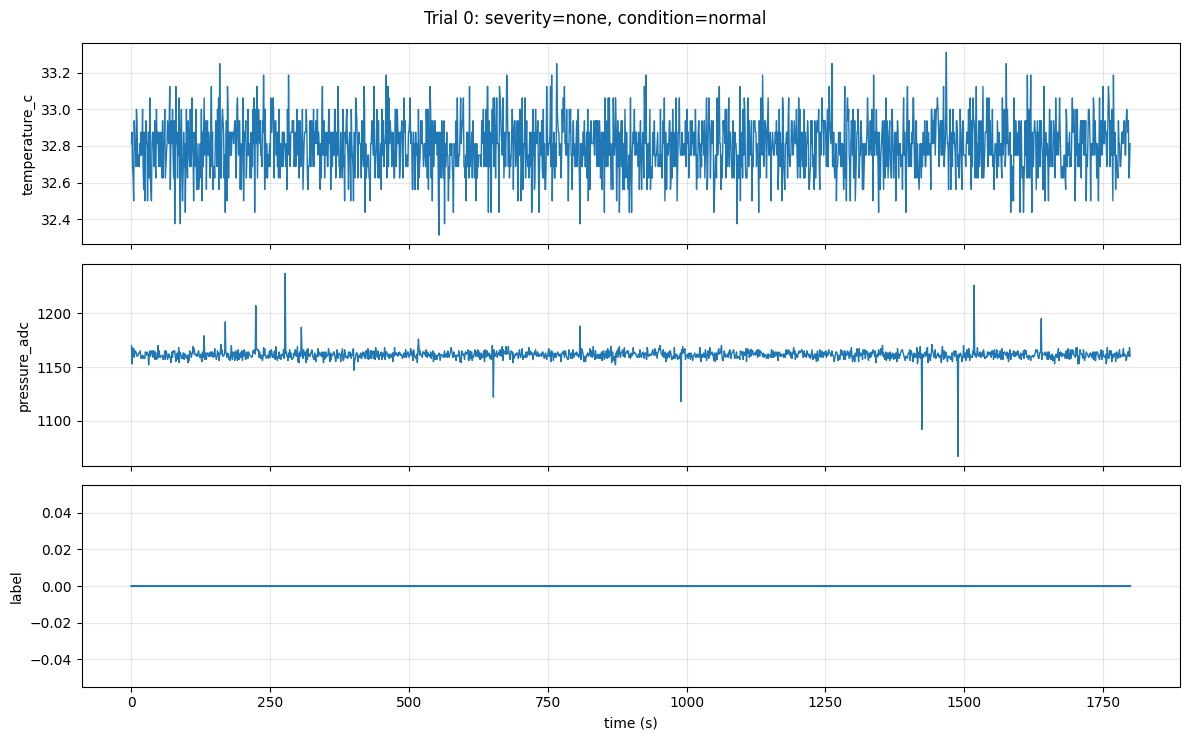

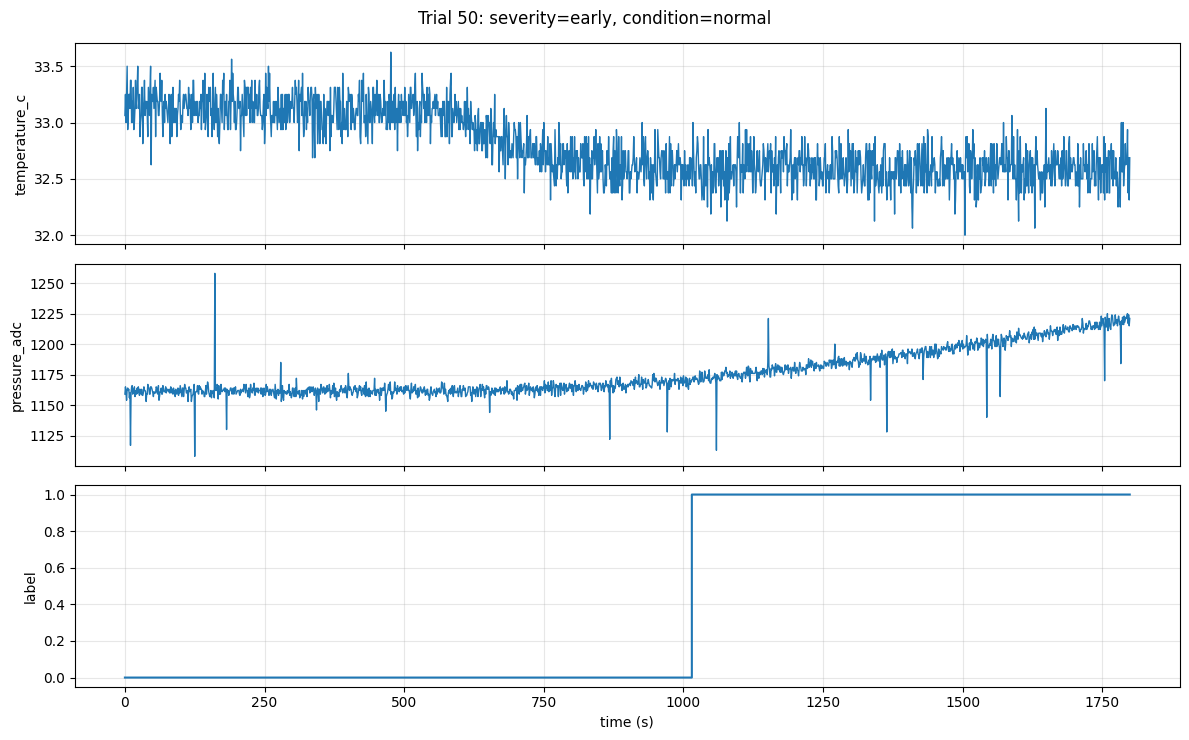

In [6]:
# Plot one non-infiltration and one infiltration trial, if available.
if sensor_cols and "severity" in df.columns:
    trial_meta = df.groupby("trial_id").first()
    none_ids = trial_meta.index[trial_meta["severity"].astype(str).str.lower() == "none"].tolist()
    inf_ids = trial_meta.index[trial_meta["severity"].astype(str).str.lower() != "none"].tolist()
    chosen = (none_ids[:1] + inf_ids[:1])

    for tid in chosen:
        g = df[df["trial_id"] == tid].sort_values("time_s")
        fig, axes = plt.subplots(len(sensor_cols) + 1, 1, figsize=(12, 2.5*(len(sensor_cols)+1)), sharex=True)
        axes = np.atleast_1d(axes)
        for ax, col in zip(axes, sensor_cols):
            ax.plot(g["time_s"], g[col], linewidth=1)
            ax.set_ylabel(col)
            ax.grid(True, alpha=0.3)
        axes[-1].step(g["time_s"], g["label"], where="post")
        axes[-1].set_ylabel("label")
        axes[-1].set_xlabel("time (s)")
        axes[-1].grid(True, alpha=0.3)
        fig.suptitle(f"Trial {tid}: severity={g['severity'].iloc[0]}, condition={g['condition'].iloc[0]}")
        plt.tight_layout()
        plt.show()

## 4. Demonstrate the current window-timestamp issue

In the experiment script, the window label is the maximum timestep label inside the window, but the timestamp is the window **start**. If a positive label begins inside a window, the model is scored as detecting infiltration at a time when it has not yet observed the whole window.

For an online prediction based on a full window, its earliest availability time is the **window end**. Fix the experiment code and rerun it before presenting detection delay or early-warning claims.

In [7]:
def inspect_window_label_timing(trial_df, window_len=50, stride=50):
    g = trial_df.sort_values("time_s").reset_index(drop=True)
    t = g["time_s"].to_numpy(dtype=float)
    y = g["label"].to_numpy(dtype=int)
    rows = []
    for start in range(0, len(g) - window_len + 1, stride):
        end = start + window_len - 1
        segment = y[start:end+1]
        positive = np.flatnonzero(segment >= 1)
        first_positive_time = t[start + positive[0]] if len(positive) else np.nan
        rows.append({
            "window_start_s": t[start],
            "window_end_s": t[end],
            "window_label_max": int(segment.max()),
            "first_positive_label_inside_window_s": first_positive_time,
            "positive_label_offset_from_window_start_s": (
                first_positive_time - t[start] if np.isfinite(first_positive_time) else np.nan
            )
        })
    return pd.DataFrame(rows)

candidate_ids = []
for tid, g in df.groupby("trial_id"):
    if "label" in g and (g["label"] >= 1).any():
        candidate_ids.append(tid)
if candidate_ids:
    print("Example infiltrating trial:", candidate_ids[0])
    display(inspect_window_label_timing(df[df["trial_id"] == candidate_ids[0]]).head(20))

Example infiltrating trial: 50


,window_start_s,window_end_s,window_label_max,first_positive_label_inside_window_s,positive_label_offset_from_window_start_s
0,0.0,49.0,0,NaN,NaN
1,50.0,99.0,0,NaN,NaN
2,100.0,149.0,0,NaN,NaN
3,150.0,199.0,0,NaN,NaN
4,200.0,249.0,0,NaN,NaN
5,250.0,299.0,0,NaN,NaN
6,300.0,349.0,0,NaN,NaN
7,350.0,399.0,0,NaN,NaN
8,400.0,449.0,0,NaN,NaN
9,450.0,499.0,0,NaN,NaN


## 5. Plot existing reported metrics (not independently reproduced)

These are loaded from the project's existing JSON. Mark these plots as **reported synthetic-data results; timing and simulator audit pending** until the experiment has been corrected and rerun.

In [8]:
metrics_path = RESULTS_B / "workstream_b_metrics.json"
metrics = None
if metrics_path.exists():
    with open(metrics_path, "r", encoding="utf-8") as f:
        metrics = json.load(f)
    print("Loaded:", metrics_path)
else:
    print("Missing:", metrics_path)

Loaded: C:\mer\iot projecttt\iv-infiltration-project\results\workstream_b\workstream_b_metrics.json


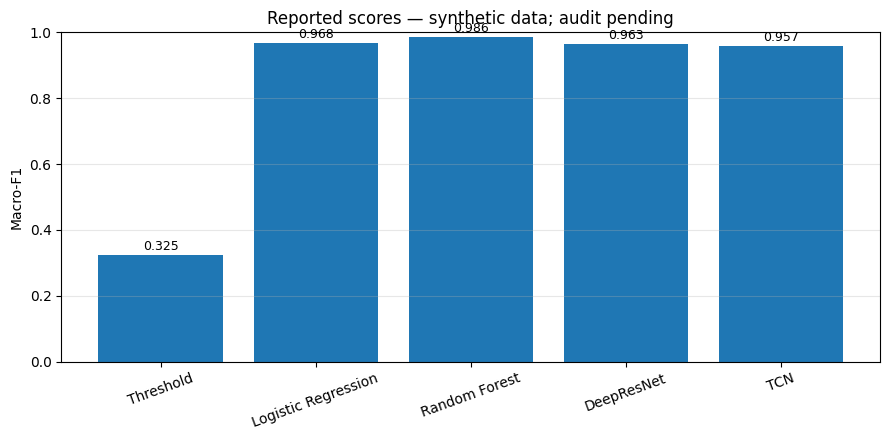

In [9]:
if metrics and "main" in metrics:
    names = ["threshold", "logistic_regression", "random_forest", "deep_resnet", "tcn"]
    labels = ["Threshold", "Logistic Regression", "Random Forest", "DeepResNet", "TCN"]
    scores = []
    for name in names:
        m = metrics["main"].get(name, {})
        scores.append(m.get("macro_f1_mean", m.get("macro_f1", np.nan)))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.bar(labels, scores)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Macro-F1")
    ax.set_title("Reported scores — synthetic data; audit pending")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
    for bar, val in zip(bars, scores):
        if np.isfinite(val):
            ax.text(bar.get_x()+bar.get_width()/2, val+0.015, f"{val:.3f}", ha="center", fontsize=9)
    plt.tight_layout()
    plt.show()

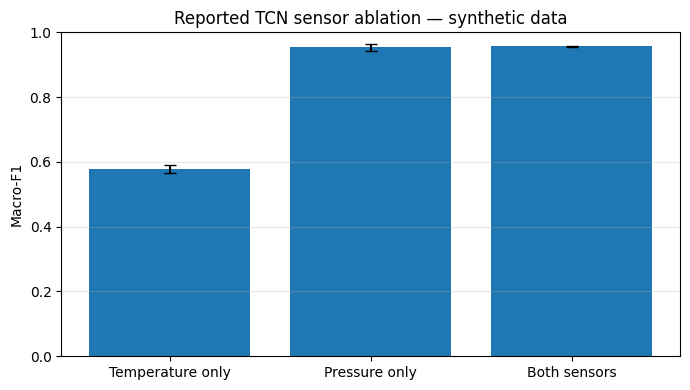

In [10]:
if metrics and "sensor_ablation" in metrics:
    ab = metrics["sensor_ablation"]
    keys = ["temp_only", "pressure_only", "temp_pressure"]
    labels = ["Temperature only", "Pressure only", "Both sensors"]
    vals = [ab[k]["macro_f1_mean"] for k in keys]
    errs = [ab[k].get("macro_f1_std", 0) for k in keys]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(labels, vals, yerr=errs, capsize=4)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Macro-F1")
    ax.set_title("Reported TCN sensor ablation — synthetic data")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## 6. Research quality gate before rerunning

- [ ] Verify timestep labels against the simulator's actual physical state and onset definition.
- [ ] Determine when each sensor starts changing relative to the defined onset and why.
- [ ] Timestamp a full-window prediction at the time the entire window is observed, not at its start.
- [ ] State whether the task is state classification or early warning; these are not the same.
- [ ] Confirm trial IDs are disjoint across train/validation/test.
- [ ] Fit normalization on training data only and reuse those parameters at inference.
- [ ] Compare Threshold, Random Forest and TCN on identical test windows and labels.
- [ ] Report per-class metrics, confusion matrix, false alarms, missed trials, detection delay and compute footprint.
- [ ] Separate literature-derived simulator assumptions from experimentally calibrated parameters.
- [ ] Do not claim clinical validation of temperature/pressure from bioimpedance-only paired clinical measurements.

## 7. Defensible conclusion template

> “We analysed paired clinical bioimpedance measurements from 18 patients to quantify pre/post-infiltration differences. Separately, we developed a physics-informed synthetic sensor simulator and evaluated candidate classifiers on trial-disjoint synthetic data. The best model achieved [verified metric] under [specified protocol]. These experiments establish feasibility within the simulated environment, not clinical diagnostic performance. The next validation step is sensor-level bench testing and prospective data collection.”

Replace bracketed items only with results that have been rerun and verified. Do not imply that clinical data directly validates temperature/pressure unless those channels were actually measured or a validated mapping exists.